[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gladiator756/ecommerce-churn-prediction/blob/main/source-code.ipynb)

# E-Commerce Customer Churn — Full ML Diagnostics
### Algorithms: Naive Bayes · MLP · SVM · Random Forest · AdaBoost · Logistic Regression (baseline)
**What this notebook does:**
- Loads the Kaggle E-Commerce Churn dataset, fixes label inconsistencies and removes duplicate rows
- Holds out a stratified **20% test set** that is never used for tuning or model selection
- Builds one leak-free pipeline per model: imputation → **SMOTENC** → scaling + one-hot encoding → classifier, all fitted inside each training fold
- Estimates performance with **true nested cross-validation** (GridSearchCV inside the outer CV loop) on the training set
- Evaluates the final tuned models once on the untouched test set: confusion matrices, ROC and PR curves
- Analyses **stability** (CV variance), **overfitting/underfitting** (train vs validation gap, learning curves) and **feature importance** (permutation importance on the test set)

**Run it in Google Colab:** click the badge above, then *Runtime → Run all*. The first cell installs the right package versions, and the dataset is downloaded from this repository automatically. On Colab the notebook runs in **quick mode** (smaller hyperparameter grids, 3 outer folds), which finishes in a few minutes. Set `QUICK_MODE = False` in Cell 0 to reproduce the full results saved below.

**Run it locally:** `pip install -r requirements.txt`, then run all cells. The dataset is read from `data/E_Commerce_Dataset.xlsx`.

## Cell 0 — Setup

In [1]:
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Quick mode: smaller grids and fewer folds so a run on Colab's free 2-core machine takes minutes.
# The saved outputs in this notebook come from the full run (QUICK_MODE = False).
QUICK_MODE = IN_COLAB

# Where to download the dataset from when it isn't available locally (e.g. on Colab)
GITHUB_USER = "gladiator756"
GITHUB_REPO = "ecommerce-churn-prediction"
DATA_URL = os.environ.get(
    "ECOMMERCE_DATA_URL",
    f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/main/data/E_Commerce_Dataset.xlsx")

if IN_COLAB:
    # Match the library versions the notebook was written for (see requirements.txt)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "scikit-learn==1.8.0", "imbalanced-learn==0.14.1"], check=True)

print(f"Running on Colab : {IN_COLAB}")
print(f"Quick mode       : {QUICK_MODE}")

Running on Colab : False
Quick mode       : False


## Cell 1 — Imports

In [2]:
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, average_precision_score,
                             precision_recall_curve)
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

PALETTE = {
    "Naive Bayes":         "#E07B54",
    "MLP":                 "#5B8DB8",
    "SVM":                 "#6DBF82",
    "Random Forest":       "#A97BBF",
    "AdaBoost":            "#F0C040",
    "Logistic Regression": "#8B8B8B",
}

print("✔ All libraries imported successfully.")

✔ All libraries imported successfully.


Library versions are pinned in `requirements.txt`. The `PALETTE` dict assigns a consistent colour to each model so all charts are visually coherent. `RANDOM_STATE` is used everywhere so the results are reproducible.

## Cell 2 — Load the Dataset

In [3]:
# Look for the file in data/ or next to the notebook, under either of its common names.
# Set the ECOMMERCE_DATA environment variable to override.
# If it isn't found (e.g. on Colab), download it from the GitHub repository (DATA_URL, Cell 0).
CANDIDATES = ["E_Commerce_Dataset.xlsx", "E Commerce Dataset.xlsx"]
SEARCH_DIRS = [Path.cwd() / "data", Path.cwd()]

if os.environ.get("ECOMMERCE_DATA"):
    DATA_PATH = Path(os.environ["ECOMMERCE_DATA"])
else:
    DATA_PATH = next((d / name for d in SEARCH_DIRS for name in CANDIDATES
                      if (d / name).exists()), None)

if DATA_PATH is None:
    DATA_PATH = SEARCH_DIRS[0] / CANDIDATES[0]
    DATA_PATH.parent.mkdir(exist_ok=True)
    print(f"Downloading dataset from {DATA_URL} ...")
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    except Exception as err:
        raise FileNotFoundError(
            f"Dataset not found locally and the download failed ({err}). Place one of "
            f"{CANDIDATES} in {SEARCH_DIRS[0]}, or check GITHUB_USER / GITHUB_REPO in Cell 0.") from err
elif not DATA_PATH.exists():
    raise FileNotFoundError(f"ECOMMERCE_DATA points to a missing file: {DATA_PATH}")

SHEET = "E Comm"
df_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET)

print(f"Loaded        : {DATA_PATH.name}")
print(f"Dataset shape : {df_raw.shape}")
print(f"\nMissing values:\n{df_raw.isnull().sum()[df_raw.isnull().sum() > 0]}")
print(f"\nClass distribution:\n{df_raw['Churn'].value_counts()}")
print(f"\nChurn rate    : {df_raw['Churn'].mean()*100:.1f}%")

print("\n── Descriptive Statistics ──")
print(df_raw.drop(columns=["CustomerID"]).describe().T.round(2).to_string())

skew_vals = (df_raw.drop(columns=["CustomerID", "Churn"])
             .select_dtypes(include="number").skew().sort_values(ascending=False))
print("\n── Feature Skewness (|skew| > 1 = highly skewed) ──")
print(skew_vals.round(3).to_string())

Loaded        : E_Commerce_Dataset.xlsx
Dataset shape : (5630, 20)

Missing values:
Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64

Class distribution:
Churn
0    4682
1     948
Name: count, dtype: int64

Churn rate    : 16.8%

── Descriptive Statistics ──
                              count    mean    std   min     25%     50%     75%     max
Churn                        5630.0    0.17   0.37   0.0    0.00    0.00    0.00    1.00
Tenure                       5366.0   10.19   8.56   0.0    2.00    9.00   16.00   61.00
CityTier                     5630.0    1.65   0.92   1.0    1.00    1.00    3.00    3.00
WarehouseToHome              5379.0   15.64   8.53   5.0    9.00   14.00   20.00  127.00
HourSpendOnApp               5375.0    2.93   0.72   0.0    2.00    3.00    3.00    5.0

The dataset has **5,630 rows and 20 columns**. The churn rate is **16.8%** (948 churners vs 4,682 non-churners), so the classes are imbalanced. We handle this with SMOTENC inside the pipeline (Cell 6).

**Descriptive statistics — discussion (Section 1.1)**

**Missing values:** seven numeric columns (`Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount`, `DaySinceLastOrder`) are each missing about 250–310 values (roughly 4.5–5.5%). They are imputed inside the pipeline (Cell 6), so the imputation statistics are learned from training folds only.

**Right-skewed features (skew > 1):**
- **CouponUsed** (skew 2.55) and **OrderCount** (skew 2.20): most customers have one or two of each, with a long tail up to 16.
- **WarehouseToHome** (skew 1.62): median 14 km and 75th percentile 20 km, but the maximum is 127 km, so there are clear outliers. Because of this skew we impute with the **median** rather than the mean.
- **DaySinceLastOrder** (skew 1.19, max 46 days) and **CashbackAmount** (skew 1.15).
- **NumberOfAddress** (skew 1.09): median 3, but one customer has 22 addresses.

**Narrow or ordinal features:**
- **SatisfactionScore** takes values 1–5 (mean 3.07), and **CityTier** takes values 1–3. Both are ordinal, so they stay numeric.
- **Complain** is a 0/1 flag. We treat it as categorical so that SMOTENC never creates fractional values such as 0.4 for it.

**Scale differences:** **CashbackAmount** (mean 177, std 49) and **HourSpendOnApp** (mean 2.9, std 0.7) are on very different scales. **StandardScaler** puts every numeric feature on mean 0 and std 1, so large-scale features don't dominate distance- and gradient-based models (SVM, MLP, Logistic Regression). Tree ensembles are unaffected by scaling.

## Cell 3 — Cleaning (Consistency Fixes · Duplicates)

In [4]:
df = df_raw.drop(columns=["CustomerID"])

# ── Fix label inconsistencies: the same category is spelled in two ways ──
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Mobile Phone": "Phone"})
df["PreferedOrderCat"]     = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace(
    {"CC": "Credit Card", "COD": "Cash on Delivery"})

# ── Remove exact duplicate rows (identical once CustomerID is dropped) ──
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

CAT_COLS = list(df.drop(columns=["Churn"]).select_dtypes(exclude="number").columns) + ["Complain"]
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + ["Churn"]]

X = df.drop(columns=["Churn"])
y = df["Churn"]

print(f"Duplicate rows removed : {n_dup}")
print(f"Rows remaining         : {len(df)}")
print(f"Class balance          : {y.value_counts().to_dict()}  (churn rate {y.mean()*100:.1f}%)")
print(f"\nCategorical columns ({len(CAT_COLS)}): {CAT_COLS}")
print(f"Numeric columns     ({len(NUM_COLS)}): {NUM_COLS}")
for col in CAT_COLS[:-1]:
    print(f"  {col}: {sorted(df[col].dropna().unique())}")

Duplicate rows removed : 557
Rows remaining         : 5073
Class balance          : {0: 4232, 1: 841}  (churn rate 16.6%)

Categorical columns (6): ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus', 'Complain']
Numeric columns     (12): ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
  PreferredLoginDevice: ['Computer', 'Phone']
  PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
  Gender: ['Female', 'Male']
  PreferedOrderCat: ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
  MaritalStatus: ['Divorced', 'Married', 'Single']


- **CustomerID** is dropped because it is an identifier with no predictive value.
- **Consistency fixes:** the raw data spells the same category in two ways (`"Mobile Phone"`/`"Phone"`, `"Mobile"`/`"Mobile Phone"`, `"CC"`/`"Credit Card"`, `"COD"`/`"Cash on Delivery"`). We merge each pair before modelling. These are fixed rules that learn nothing from the data, so applying them before the split doesn't leak information.
- **Duplicates:** 556 rows are exact copies of another row once `CustomerID` is removed, and merging the spellings above reveals one more, so 557 rows are dropped. If we kept them, copies of the same customer profile could land in both a training fold and a test fold. The model would then be scored partly on rows it has already memorised, which especially inflates tree models like Random Forest. We drop them **before** any split.
- **No imputation or encoding happens here.** Both are learned steps, so they live inside the model pipeline (Cell 6) and are re-fitted on each training fold.

## Cell 4 — Hold-out Test Set & CV Strategy

In [5]:
# 20% stratified hold-out set: never used for tuning, model selection or learning curves.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# Outer CV: performance estimation (nested CV) on the training set
N_OUTER = 3 if QUICK_MODE else 5
CV_OUTER = StratifiedKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_STATE)
# Inner CV: hyperparameter tuning inside GridSearchCV
CV_INNER = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

SCORING = ["accuracy", "f1", "roc_auc", "precision", "recall", "average_precision"]

print(f"Train set : {X_train.shape[0]} rows  (churn rate {y_train.mean()*100:.1f}%)")
print(f"Test set  : {X_test.shape[0]} rows  (churn rate {y_test.mean()*100:.1f}%)")
print(f"Outer folds : {N_OUTER}  |  Inner folds : 3  |  Scoring : {SCORING}")
if QUICK_MODE:
    print("QUICK MODE: 3 outer folds instead of 5 — the text below describes the full 5-fold run")

Train set : 4058 rows  (churn rate 16.6%)
Test set  : 1015 rows  (churn rate 16.6%)
Outer folds : 5  |  Inner folds : 3  |  Scoring : ['accuracy', 'f1', 'roc_auc', 'precision', 'recall', 'average_precision']


The data is split once into an **80% training set** and a **20% test set**. The test set is stored away and used only once, in Cell 10, after every modelling decision has been made.

On the training set we use **Stratified K-Fold** because the classes are imbalanced. Stratification keeps the churn ratio the same in every fold. The **5 outer folds** estimate performance, and the **3 inner folds** run inside `GridSearchCV` to choose hyperparameters. Because the grid search is re-run from scratch inside every outer training fold (Cell 7), the outer validation fold never influences which hyperparameters are chosen. That is what makes the cross-validation **nested**.

## Cell 5 — Preprocessing Pipeline

In [6]:
n_num, n_cat = len(NUM_COLS), len(CAT_COLS)
CAT_IDX = list(range(n_num, n_num + n_cat))   # positions of categorical columns after step 1

def make_pipeline(clf):
    # Every learned step is fitted on the training fold only:
    #   1. impute   — median for numerics; mode + integer codes for categoricals
    #   2. smote    — SMOTENC oversamples churners; categorical columns get a real category
    #                 (the most common among neighbours), never an interpolated code
    #   3. encode   — StandardScaler for numerics, one-hot for categoricals
    #   4. clf      — the classifier
    impute = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
        ("cat", Pipeline([("mode", SimpleImputer(strategy="most_frequent")),
                          ("codes", OrdinalEncoder())]), CAT_COLS),
    ])
    encode = ColumnTransformer([
        ("num", StandardScaler(), list(range(n_num))),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT_IDX),
    ])
    return ImbPipeline([
        ("impute", impute),
        ("smote",  SMOTENC(categorical_features=CAT_IDX, random_state=RANDOM_STATE)),
        ("encode", encode),
        ("clf",    clf),
    ])

def churn_scores(model, X_):
    # Continuous churn score for ROC/PR curves: probability if available, else SVM margin
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

make_pipeline(LogisticRegression())

,steps,"[('impute', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given

Earlier versions of this notebook imputed and label-encoded the whole dataset before cross-validation, then applied plain SMOTE. That caused three problems, which this pipeline fixes:

| Problem | Fix |
|---|---|
| Median/mode imputation saw the test folds | `SimpleImputer` is a pipeline step, fitted on each training fold only |
| Label encoding gave nominal categories (e.g. payment mode) an arbitrary order that SVM, MLP and Logistic Regression treat as meaningful | `OneHotEncoder`: one binary column per category, so no order is implied |
| SMOTE interpolated between integer codes and created categories that don't exist (e.g. a code of 2.4) | `SMOTENC`: categorical columns of synthetic samples take a real category |

SMOTENC runs **before** one-hot encoding, on integer category codes it treats as categorical, so synthetic rows always get a valid category. The `imblearn` pipeline applies SMOTENC only during `fit`. Validation and test rows are never oversampled.

`churn_scores` returns a probability when the model has one. SVM is trained without `probability=True` (which would add an internal 5-fold calibration and slow tuning down a lot), so its decision margin is used instead. ROC-AUC and PR-AUC depend only on how the scores rank the samples, so this doesn't change them.

## Cell 6 — Models & Hyperparameter Grids

In [7]:
BASE_MODELS = {
    # Gaussian likelihood per feature, assumes features are conditionally independent
    "Naive Bayes": make_pipeline(GaussianNB()),
    # Feed-forward network; early_stopping holds out 10% of the training fold to stop overfitting
    "MLP": make_pipeline(MLPClassifier(max_iter=500, early_stopping=True,
                                       random_state=RANDOM_STATE)),
    # Maximum-margin classifier; class_weight compensates for any remaining imbalance
    "SVM": make_pipeline(SVC(class_weight="balanced", random_state=RANDOM_STATE)),
    # Bagged ensemble of decision trees
    "Random Forest": make_pipeline(RandomForestClassifier(class_weight="balanced",
                                                          random_state=RANDOM_STATE)),
    # Sequential boosting of shallow trees, focusing on misclassified samples
    "AdaBoost": make_pipeline(AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2),
                                                 random_state=RANDOM_STATE)),
    # Linear baseline: P(churn) through a sigmoid
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced",
                                                            random_state=RANDOM_STATE)),
}

PARAM_GRIDS = {
    "Naive Bayes": {"clf__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5]},
    "MLP": {
        "clf__hidden_layer_sizes": [(64,), (128, 64)],
        "clf__alpha":              [0.0001, 0.001, 0.01],
        "clf__learning_rate_init": [0.001, 0.01],
    },
    "SVM": [
        {"clf__kernel": ["rbf"],    "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", "auto"]},
        {"clf__kernel": ["linear"], "clf__C": [0.1, 1, 10]},
    ],
    "Random Forest": {
        "clf__n_estimators":      [100, 200],
        "clf__max_depth":         [10, 20, None],
        "clf__min_samples_split": [2, 5],
    },
    "AdaBoost": {
        "clf__n_estimators":  [50, 100, 200],
        "clf__learning_rate": [0.5, 1.0, 1.5],
    },
    # l1_ratio: 0 = L2 penalty, 1 = L1 penalty (sparse coefficients); liblinear supports both
    "Logistic Regression": {
        "clf__C":        [0.01, 0.1, 1, 10],
        "clf__l1_ratio": [0.0, 1.0],
        "clf__solver":   ["liblinear"],
    },
}

# Quick mode: two candidates per model (always including the setting the full run picked)
QUICK_GRIDS = {
    "Naive Bayes":         {"clf__var_smoothing": [1e-9, 1e-5]},
    "MLP":                 {"clf__hidden_layer_sizes": [(64,), (128, 64)], "clf__alpha": [0.001],
                            "clf__learning_rate_init": [0.01]},
    "SVM":                 {"clf__kernel": ["rbf"], "clf__C": [1, 10], "clf__gamma": ["scale"]},
    "Random Forest":       {"clf__n_estimators": [200], "clf__max_depth": [20, None]},
    "AdaBoost":            {"clf__n_estimators": [200], "clf__learning_rate": [0.5, 1.5]},
    "Logistic Regression": {"clf__C": [0.1, 1], "clf__l1_ratio": [1.0], "clf__solver": ["liblinear"]},
}
if QUICK_MODE:
    PARAM_GRIDS = QUICK_GRIDS

def make_search(name):
    return GridSearchCV(BASE_MODELS[name], PARAM_GRIDS[name], cv=CV_INNER,
                        scoring="roc_auc", n_jobs=-1, refit=True)

model_names = list(BASE_MODELS)
print("Models:", model_names)

Models: ['Naive Bayes', 'MLP', 'SVM', 'Random Forest', 'AdaBoost', 'Logistic Regression']


| Model | Parameters searched | Why chosen |
|---|---|---|
| Naive Bayes | `var_smoothing` | Fast probabilistic baseline; smoothing avoids zero variances |
| MLP | `hidden_layer_sizes`, `alpha`, `learning_rate_init` | Captures non-linear patterns; depth/regularisation trade-off |
| SVM | `kernel`, `C`, `gamma` (rbf only) | Maximum-margin classifier; the kernel controls the boundary shape |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split` | Robust ensemble, insensitive to outliers and scaling |
| AdaBoost | `n_estimators`, `learning_rate` | Boosting concentrates on hard-to-classify churners |
| Logistic Regression | `C`, `l1_ratio` (L1 vs L2 penalty) | Interpretable linear baseline |

Every search optimises **ROC-AUC** on the 3 inner folds.

## Cell 7 — Nested Cross-Validation (Train + Validation Scores)

In [8]:
# The GridSearchCV object itself is the estimator being cross-validated:
# in each outer fold, the full grid search runs on the outer training part only,
# and the refitted best model is then scored on the outer validation fold.
cv_results = {}
fold_params = {}

for name in model_names:
    print(f"Nested CV: {name} ...", end=" ", flush=True)
    res = cross_validate(
        make_search(name), X_train, y_train,
        cv=CV_OUTER, scoring=SCORING,
        return_train_score=True,   # train score of the refitted best model, for the overfitting gap
        return_estimator=True,
    )
    cv_results[name] = res
    fold_params[name] = [est.best_params_ for est in res["estimator"]]
    gap = (res["train_roc_auc"] - res["test_roc_auc"]).mean()
    print(f"AUC={res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}  "
          f"F1={res['test_f1'].mean():.4f}  Train-Val gap={gap:.4f}")

print("\n── Best hyperparameters chosen in each outer fold ──")
for name, plist in fold_params.items():
    print(f"\n  {name}:")
    for i, p in enumerate(plist, 1):
        print(f"    fold {i}: " + ", ".join(f"{k.replace('clf__','')}={v}" for k, v in p.items()))

Nested CV: Naive Bayes ... 

AUC=0.7691 ± 0.0306  F1=0.4114  Train-Val gap=0.0086
Nested CV: MLP ... 

AUC=0.9653 ± 0.0103  F1=0.8143  Train-Val gap=0.0326
Nested CV: SVM ... 

AUC=0.9633 ± 0.0100  F1=0.8083  Train-Val gap=0.0343
Nested CV: Random Forest ... 

AUC=0.9752 ± 0.0059  F1=0.8270  Train-Val gap=0.0248
Nested CV: AdaBoost ... 

AUC=0.9355 ± 0.0218  F1=0.6908  Train-Val gap=0.0439
Nested CV: Logistic Regression ... 

AUC=0.8832 ± 0.0204  F1=0.5826  Train-Val gap=0.0083

── Best hyperparameters chosen in each outer fold ──

  Naive Bayes:
    fold 1: var_smoothing=1e-05
    fold 2: var_smoothing=1e-05
    fold 3: var_smoothing=1e-05
    fold 4: var_smoothing=1e-05
    fold 5: var_smoothing=1e-05

  MLP:
    fold 1: alpha=0.001, hidden_layer_sizes=(128, 64), learning_rate_init=0.01
    fold 2: alpha=0.0001, hidden_layer_sizes=(128, 64), learning_rate_init=0.01
    fold 3: alpha=0.01, hidden_layer_sizes=(128, 64), learning_rate_init=0.01
    fold 4: alpha=0.0001, hidden_layer_sizes=(128, 64), learning_rate_init=0.01
    fold 5: alpha=0.001, hidden_layer_sizes=(128, 64), learning_rate_init=0.01

  SVM:
    fold 1: C=10, gamma=scale, kernel=rbf
    fold 2: C=10, gamma=scale, kernel=rbf
    fold 3: C=10, gamma=scale, kernel=rbf
    fold 4: C=10, gamma=scale, kernel=rbf
    fold 5: C=10, gamma=scale, kernel=rbf

  Random Forest:
    fold 1: max_depth=None, min_samples_split=2, n_estimators=200
    fold 2:

This is **nested** cross-validation: hyperparameters are chosen without ever looking at the fold they are scored on. The scores below are therefore an unbiased estimate of how the *whole procedure* (tuning included) performs on unseen customers.

The fold-by-fold best parameters also show how stable the tuning is. If the same parameters win in every fold, the choice is robust. If they change from fold to fold, several settings perform about equally well.

The **ROC-AUC** train-validation gap (Δ) is the overfitting signal used for every label in this notebook (verdict table and learning curves):
- **Δ > 0.08** → the model fits the training data much better than new data (**high overfitting risk**)
- **0.02 ≤ Δ ≤ 0.08** → some overfitting, within an acceptable range (**medium**)
- **Δ < 0.02** → train and validation scores are close (**low overfitting risk**)

**Underfitting** shows up differently: as low scores on *both* sets (here, ROC-AUC < 0.70), not as a gap.

## Cell 8 — Metrics Summary Table & Bar Chart

Nested 5-fold CV on the training set (validation-fold means):

                     Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  Train-Val AUC Gap (Δ)  CV Std (stability)
Model                                                                                                               
Random Forest          0.9436     0.8420  0.8128  0.8270   0.9752  0.8993                 0.0248              0.0263
MLP                    0.9364     0.7918  0.8395  0.8143   0.9653  0.8806                 0.0326              0.0316
SVM                    0.9349     0.7893  0.8291  0.8083   0.9633  0.8600                 0.0343              0.0179
AdaBoost               0.9002     0.7147  0.6702  0.6908   0.9355  0.7809                 0.0439              0.0333
Logistic Regression    0.8135     0.4630  0.7860  0.5826   0.8832  0.6834                 0.0083              0.0212
Naive Bayes            0.6516     0.2864  0.7326  0.4114   0.7691  0.4932                 0.0086              0.0312


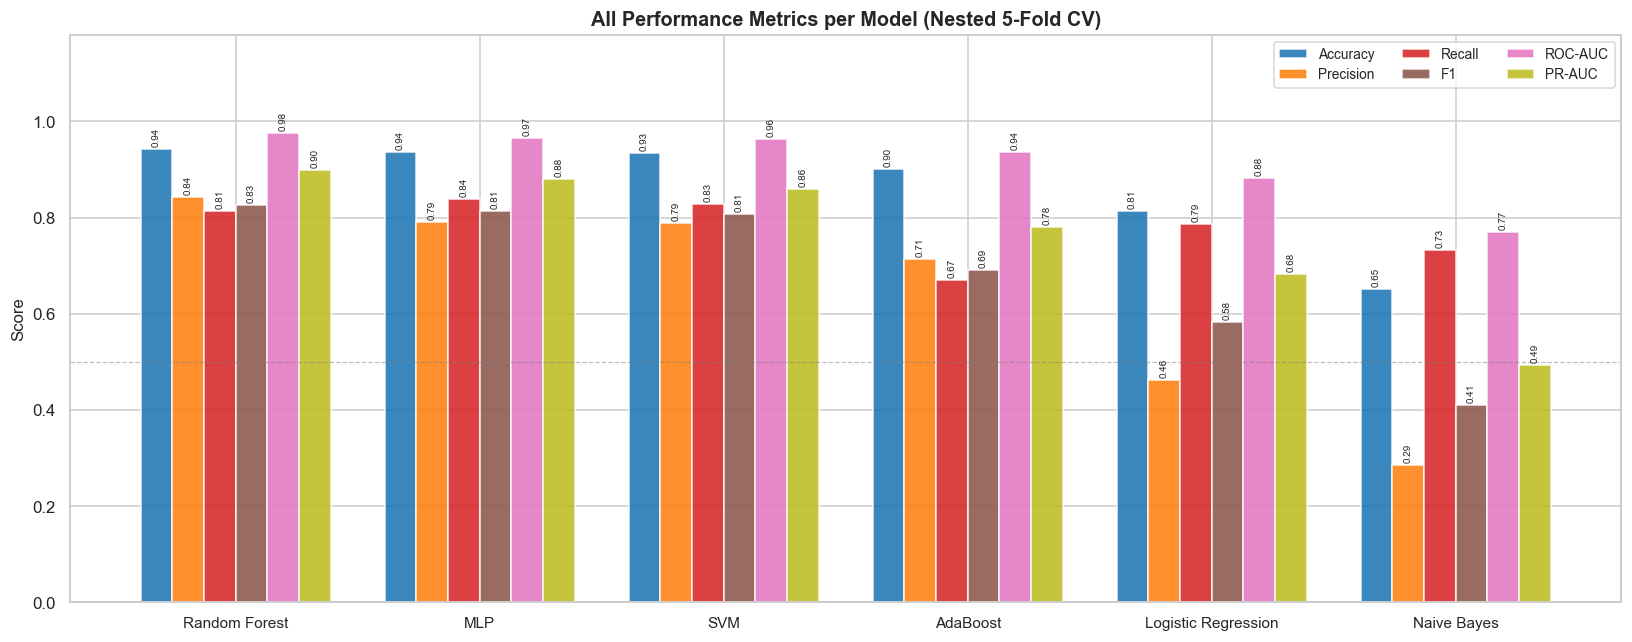

In [9]:
rows = []
for name, res in cv_results.items():
    gap  = (res["train_roc_auc"] - res["test_roc_auc"]).mean()
    stab = np.mean([res[f"test_{m}"].std() for m in ["accuracy", "f1", "roc_auc", "precision", "recall"]])
    rows.append({
        "Model":              name,
        "Accuracy":           res["test_accuracy"].mean(),
        "Precision":          res["test_precision"].mean(),
        "Recall":             res["test_recall"].mean(),
        "F1":                 res["test_f1"].mean(),
        "ROC-AUC":            res["test_roc_auc"].mean(),
        "PR-AUC":             res["test_average_precision"].mean(),
        "Train-Val AUC Gap (Δ)":  gap,
        "CV Std (stability)": stab,
    })

summary = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
model_names_sorted = list(summary.index)
print(f"Nested {N_OUTER}-fold CV on the training set (validation-fold means):\n")
print(summary.round(4).to_string())

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
x = np.arange(len(model_names_sorted))
w = 0.13
fig, ax = plt.subplots(figsize=(15, 6))
for i, metric in enumerate(metrics_to_plot):
    vals = [summary.loc[m, metric] for m in model_names_sorted]
    bars = ax.bar(x + i*w, vals, w, label=metric, color=plt.cm.tab10(i/len(metrics_to_plot)),
                  alpha=0.88, edgecolor="white")
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005, f"{val:.2f}",
                ha="center", va="bottom", fontsize=6.5, rotation=90)
ax.set_xticks(x + w*(len(metrics_to_plot)-1)/2)
ax.set_xticklabels(model_names_sorted, fontsize=10)
ax.set_ylim(0, 1.18)
ax.set_ylabel("Score", fontsize=11)
ax.set_title(f"All Performance Metrics per Model (Nested {N_OUTER}-Fold CV)", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", fontsize=9, ncol=3)
ax.axhline(0.5, color="gray", ls="--", lw=0.8, alpha=0.5)
plt.tight_layout()
plt.show()

Key columns to read:
- **ROC-AUC / PR-AUC:** ranking quality, our primary metrics (higher means better at separating churners from non-churners). PR-AUC is the stricter of the two on imbalanced data.
- **F1:** the balance between catching churners (recall) and avoiding false alarms (precision) at the default threshold.
- **Train-Val AUC Gap Δ:** the overfitting signal, the ROC-AUC gap defined in Cell 7.
- **CV Std:** stability. A low std means the model performs consistently across different data splits.

In the chart, each group of bars is one model. Watch for models whose accuracy is high but recall and F1 are low: they are mostly predicting "stay" and missing the churners.

## Cell 9 — Train vs Validation Gap (Overfitting / Underfitting)

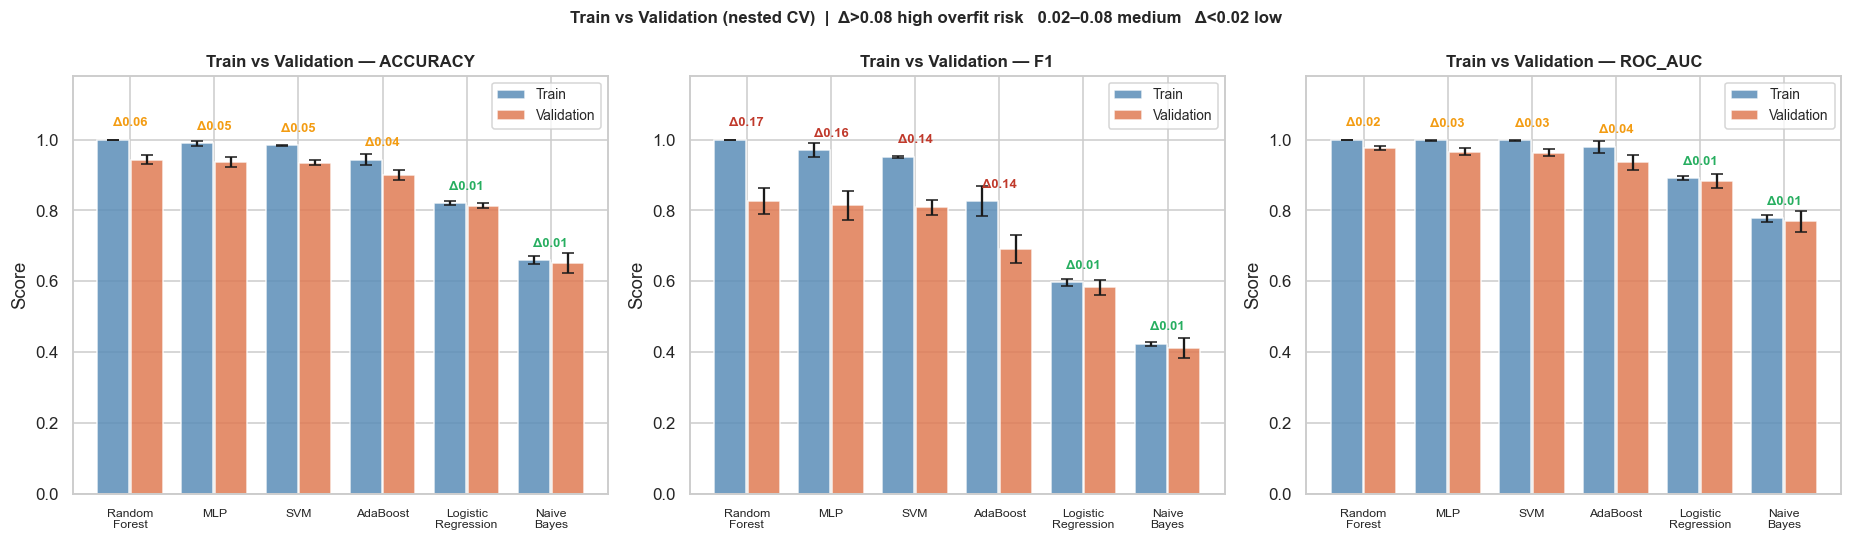

In [10]:
train_test_metrics = ["accuracy", "f1", "roc_auc"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(axes, train_test_metrics):
    train_means = [cv_results[n][f"train_{metric}"].mean() for n in model_names_sorted]
    test_means  = [cv_results[n][f"test_{metric}"].mean()  for n in model_names_sorted]
    train_stds  = [cv_results[n][f"train_{metric}"].std()  for n in model_names_sorted]
    test_stds   = [cv_results[n][f"test_{metric}"].std()   for n in model_names_sorted]
    xpos = np.arange(len(model_names_sorted))

    ax.bar(xpos-0.2, train_means, 0.38, label="Train", color="#5B8DB8", alpha=0.85,
           edgecolor="white", yerr=train_stds, capsize=4)
    ax.bar(xpos+0.2, test_means, 0.38, label="Validation", color="#E07B54", alpha=0.85,
           edgecolor="white", yerr=test_stds, capsize=4)

    for i, (tr, te) in enumerate(zip(train_means, test_means)):
        gap = tr - te
        color = "#C0392B" if gap > 0.08 else ("#27AE60" if gap < 0.02 else "#F39C12")
        ax.text(i, max(tr, te)+0.03, f"Δ{gap:.2f}", ha="center", va="bottom",
                fontsize=8.5, color=color, fontweight="bold")

    ax.set_xticks(xpos)
    ax.set_xticklabels([n.replace(" ", "\n") for n in model_names_sorted], fontsize=8)
    ax.set_ylim(0, 1.18)
    ax.set_title(f"Train vs Validation — {metric.upper()}", fontsize=11, fontweight="bold")
    ax.legend(fontsize=9); ax.set_ylabel("Score")

plt.suptitle("Train vs Validation (nested CV)  |  Δ>0.08 high overfit risk   0.02–0.08 medium   Δ<0.02 low",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

The blue bar is the training score of each outer fold's refitted best model, and the orange bar is its score on the outer validation fold. The **Δ label** on top is the gap between them, coloured with the thresholds from Cell 7: **red** above 0.08, **orange** from 0.02 to 0.08, **green** below 0.02.

Note that the training scores are measured on SMOTE-free original training rows. Oversampling happens only inside `fit`.

The accuracy and F1 gaps are shown for completeness, but the risk labels use the ROC-AUC gap. F1 and accuracy are measured at a single 0.5 threshold, where a model that fits its training rows perfectly (training F1 = 1.0) shows a large gap even when its ranking of new customers is still excellent. ROC-AUC measures that ranking across all thresholds.

## Cell 10 — Final Models & Held-out Test Set Evaluation

── Final hyperparameters (tuned on the full training set) ──
  Naive Bayes         : var_smoothing=1e-05
  MLP                 : alpha=0.001, hidden_layer_sizes=(128, 64), learning_rate_init=0.01
  SVM                 : C=10, gamma=scale, kernel=rbf
  Random Forest       : max_depth=20, min_samples_split=2, n_estimators=200
  AdaBoost            : learning_rate=1.5, n_estimators=200
  Logistic Regression : C=0.1, l1_ratio=1.0, solver=liblinear



── Held-out test set (1015 customers, 168 churners) ──
                     Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
Model                                                                    
Random Forest          0.9635     0.9068  0.8690  0.8875   0.9818  0.9446
MLP                    0.9567     0.8523  0.8929  0.8721   0.9820  0.9198
SVM                    0.9537     0.8343  0.8988  0.8653   0.9742  0.9135
AdaBoost               0.9094     0.7436  0.6905  0.7160   0.9406  0.7907
Logistic Regression    0.7901     0.4247  0.7560  0.5439   0.8618  0.6635
Naive Bayes            0.6345     0.2719  0.7202  0.3948   0.7666  0.4823


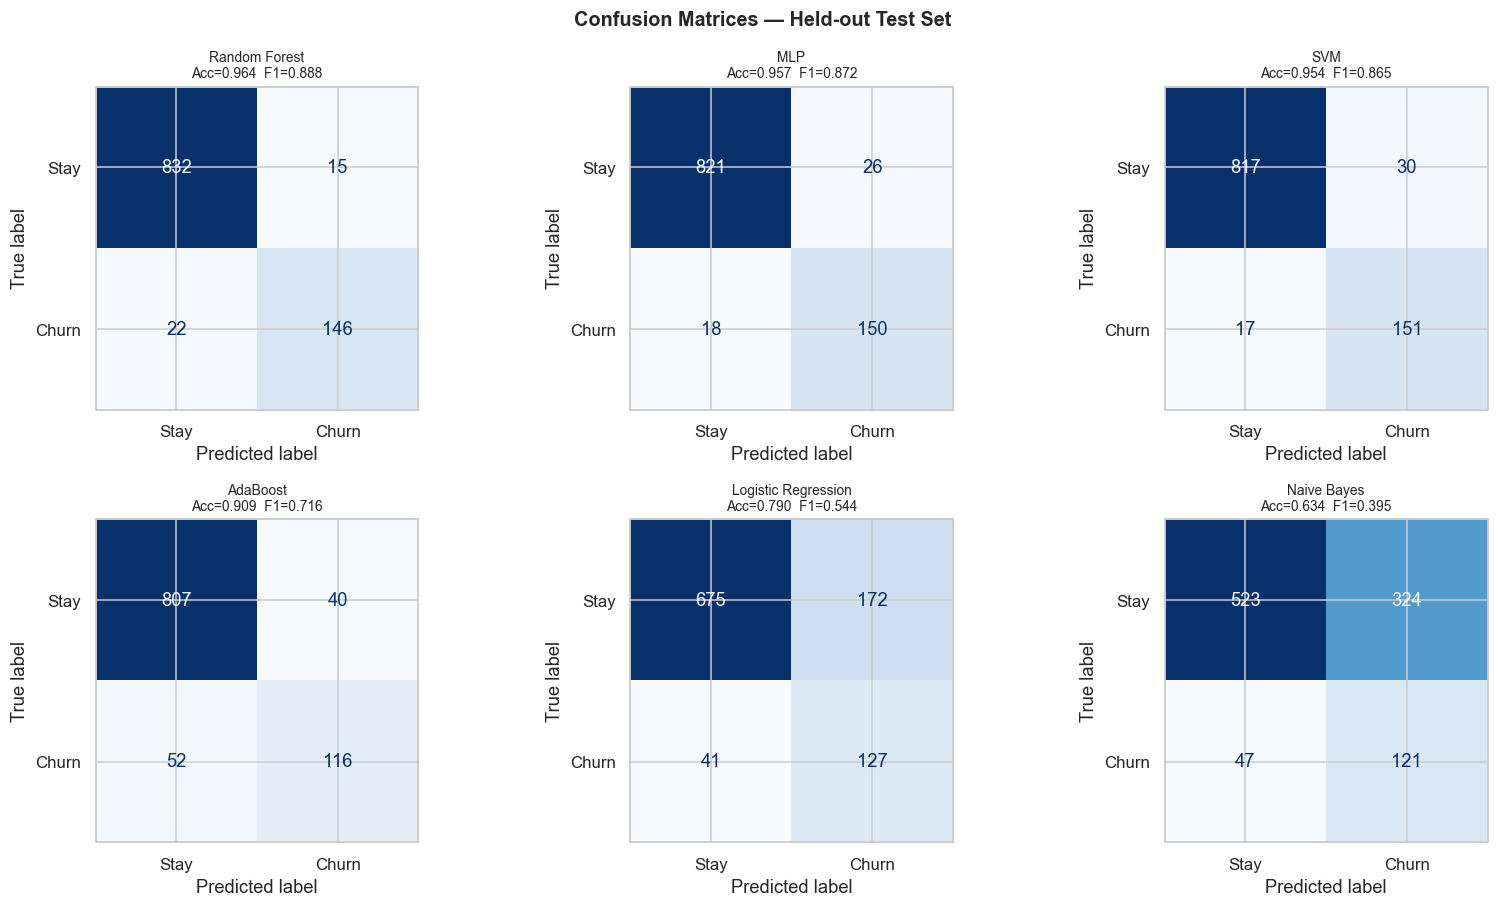

In [11]:
# Tune each model once more on the full training set, then score it ONCE on the untouched test set.
MODELS, BEST_PARAMS = {}, {}
for name in model_names:
    gs = make_search(name).fit(X_train, y_train)
    MODELS[name] = gs.best_estimator_
    BEST_PARAMS[name] = gs.best_params_

print("── Final hyperparameters (tuned on the full training set) ──")
for name, params in BEST_PARAMS.items():
    print(f"  {name:20s}: " + ", ".join(f"{k.replace('clf__','')}={v}" for k, v in params.items()))

test_rows, test_scores, test_preds = [], {}, {}
for name in model_names_sorted:
    pred  = MODELS[name].predict(X_test)
    score = churn_scores(MODELS[name], X_test)
    test_preds[name], test_scores[name] = pred, score
    test_rows.append({
        "Model":     name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall":    recall_score(y_test, pred),
        "F1":        f1_score(y_test, pred),
        "ROC-AUC":   roc_auc_score(y_test, score),
        "PR-AUC":    average_precision_score(y_test, score),
    })
test_summary = pd.DataFrame(test_rows).set_index("Model")
print(f"\n── Held-out test set ({len(y_test)} customers, {y_test.sum()} churners) ──")
print(test_summary.round(4).to_string())

# ── Confusion matrices on the test set ──
n_models = len(model_names_sorted)
ncols = 3
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4.2*nrows))
axes = np.atleast_1d(axes).flatten()
for ax, name in zip(axes, model_names_sorted):
    cm = confusion_matrix(y_test, test_preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Stay", "Churn"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nAcc={test_summary.loc[name,'Accuracy']:.3f}  F1={test_summary.loc[name,'F1']:.3f}",
                 fontsize=9)
for ax in axes[n_models:]:
    ax.axis("off")
plt.suptitle("Confusion Matrices — Held-out Test Set", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

The final models are tuned on the full training set, which is the procedure that nested CV just evaluated. Each model is then scored **once** on the 20% test set. These test-set numbers should land close to the nested-CV estimates. If they fall far below them, something is leaking into training.

**How to read the confusion matrices:**
- **Top-left (TN):** correctly predicted "Stay"
- **Top-right (FP):** predicted "Churn" but the customer stayed (a wasted retention offer)
- **Bottom-left (FN):** predicted "Stay" but the customer churned (a missed churner), usually the most costly error
- **Bottom-right (TP):** correctly predicted "Churn"

## Cell 11 — ROC Curves & PR Curves (Test Set)

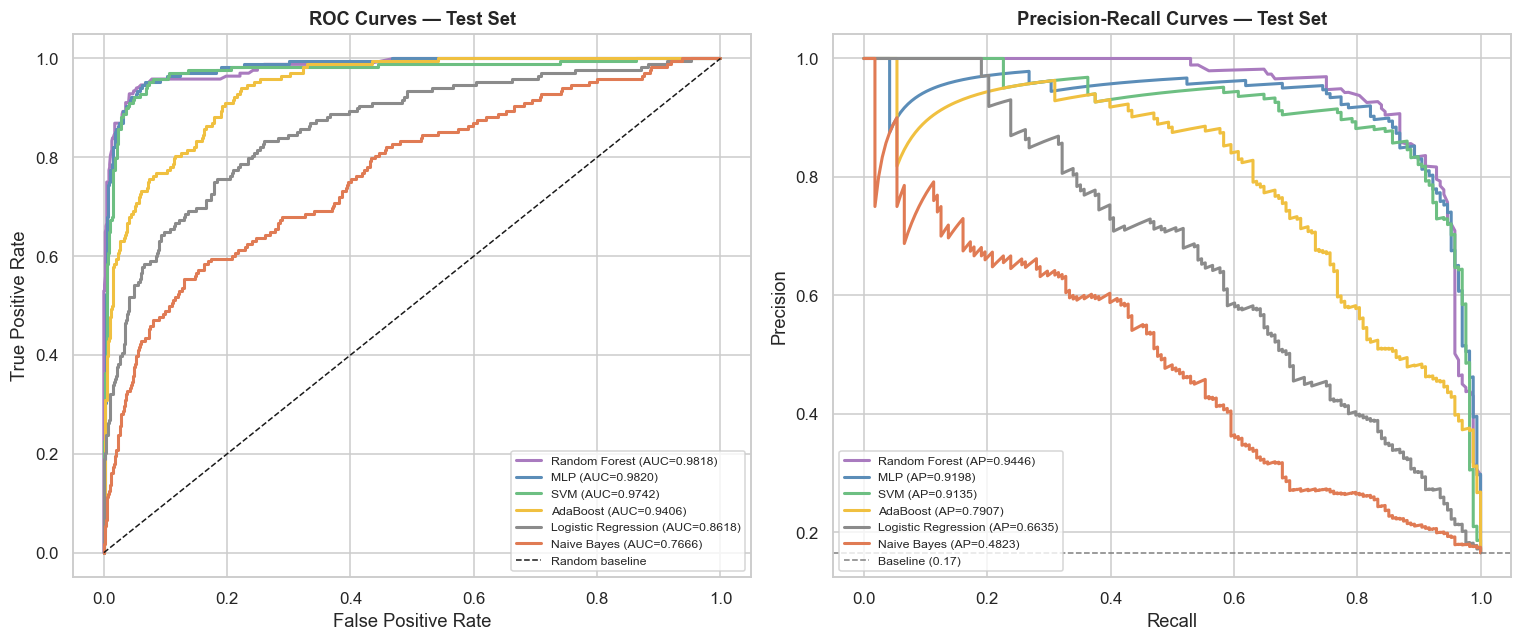

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name in model_names_sorted:
    color, score = PALETTE[name], test_scores[name]
    fpr, tpr, _ = roc_curve(y_test, score)
    axes[0].plot(fpr, tpr, lw=2, color=color,
                 label=f"{name} (AUC={test_summary.loc[name,'ROC-AUC']:.4f})")
    prec, rec, _ = precision_recall_curve(y_test, score)
    axes[1].plot(rec, prec, lw=2, color=color,
                 label=f"{name} (AP={test_summary.loc[name,'PR-AUC']:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random baseline")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves — Test Set", fontsize=12, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8)

baseline = y_test.mean()
axes[1].axhline(baseline, color="gray", ls="--", lw=1, label=f"Baseline ({baseline:.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves — Test Set", fontsize=12, fontweight="bold")
axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

- **ROC curve (left):** true positive rate against false positive rate at every decision threshold. A curve bowing toward the top-left corner is better. AUC = 0.5 is random guessing, and AUC = 1.0 is perfect.
- **PR curve (right):** more informative on imbalanced data. It shows the trade-off between precision (how many flagged customers actually churn) and recall (how many churners are caught). The grey dashed line is the no-skill baseline, equal to the test-set churn rate.

## Cell 12 — Learning Curves + Stability Boxplots

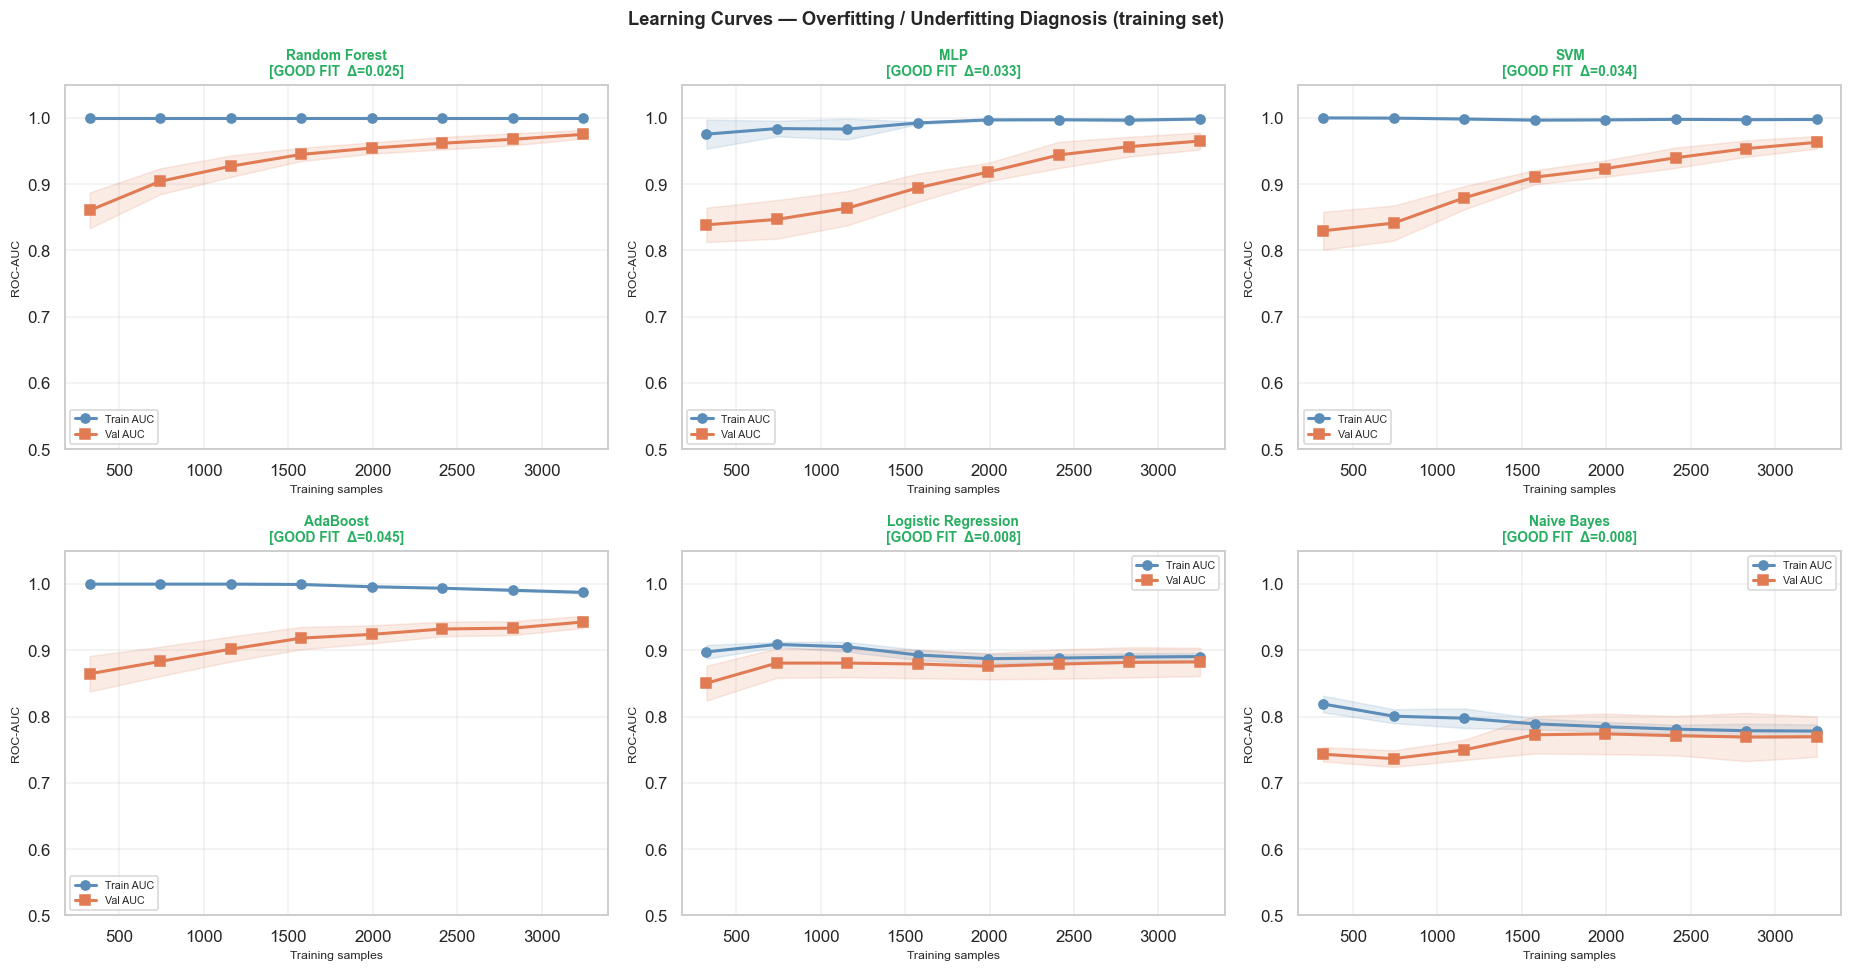

  Random Forest        GOOD FIT  final gap=0.025  val-AUC change over last step=+0.0075
  MLP                  GOOD FIT  final gap=0.033  val-AUC change over last step=+0.0085
  SVM                  GOOD FIT  final gap=0.034  val-AUC change over last step=+0.0095
  AdaBoost             GOOD FIT  final gap=0.045  val-AUC change over last step=+0.0093
  Logistic Regression  GOOD FIT  final gap=0.008  val-AUC change over last step=+0.0008
  Naive Bayes          GOOD FIT  final gap=0.008  val-AUC change over last step=+0.0005


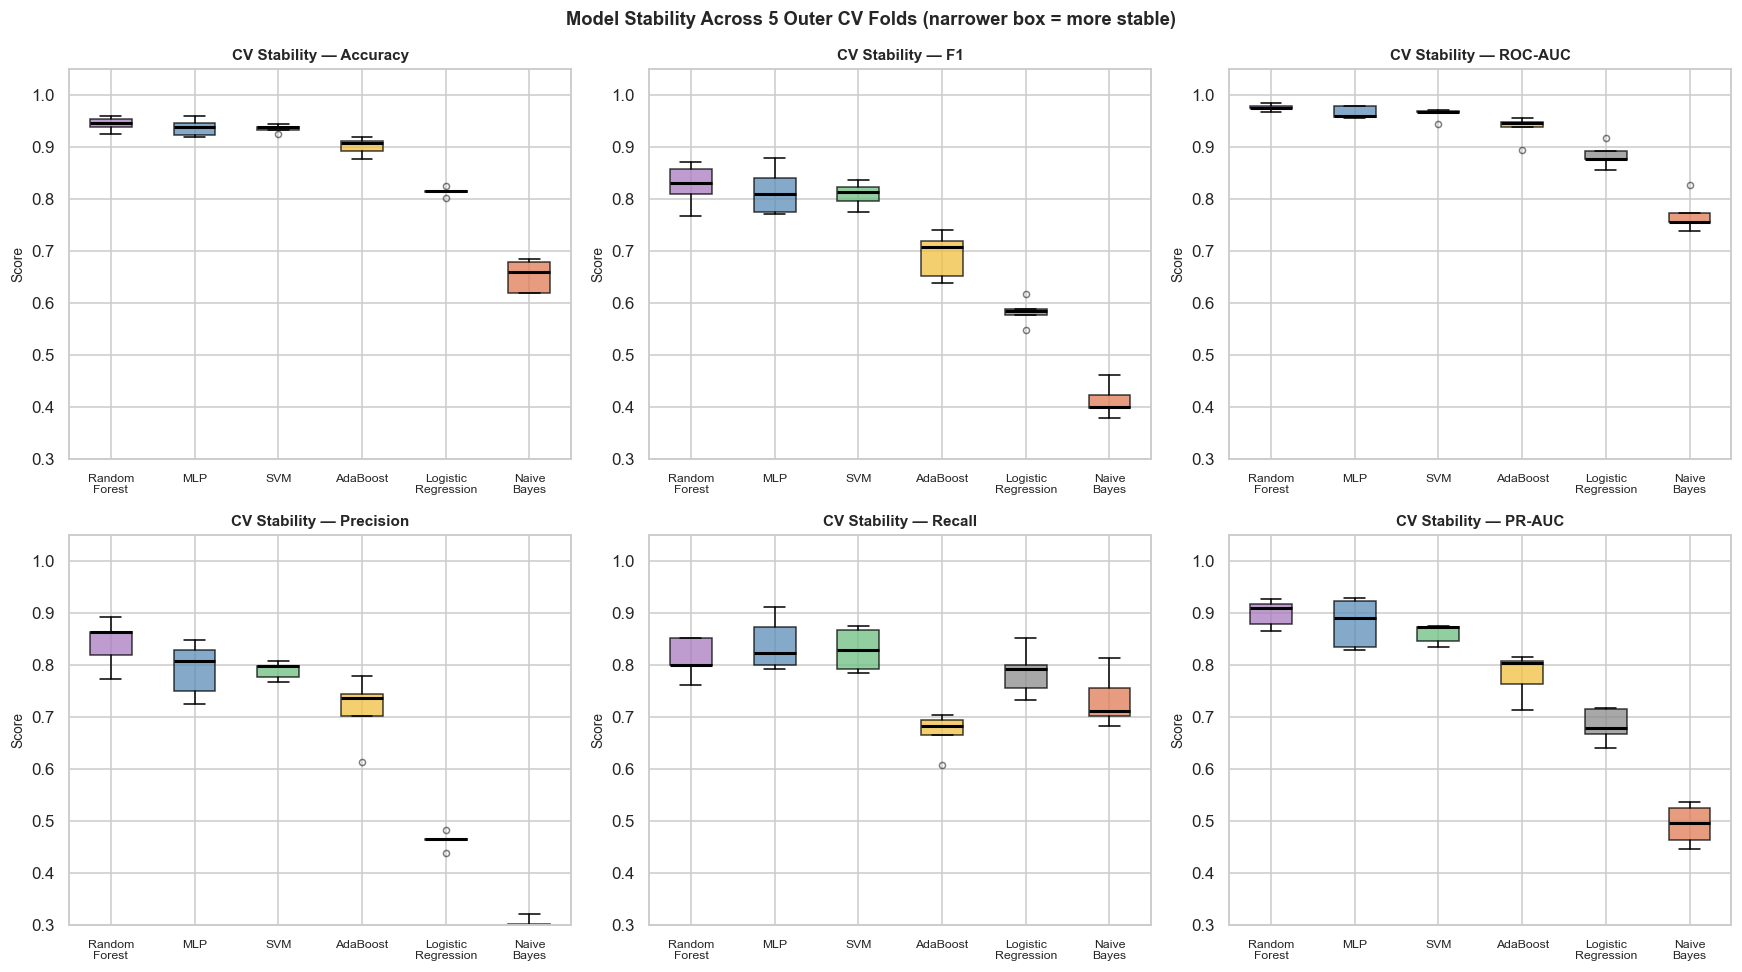

In [13]:
# Learning curves use the training set only, with each model's final hyperparameters fixed.
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()
lc_diagnosis = {}

for ax, name in zip(axes, model_names_sorted):
    train_sizes, train_scores, val_scores = learning_curve(
        MODELS[name], X_train, y_train, cv=CV_OUTER,
        train_sizes=np.linspace(0.1, 1.0, 5 if QUICK_MODE else 8), scoring="roc_auc", n_jobs=-1)
    tr_mean, tr_std   = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1),   val_scores.std(axis=1)

    ax.plot(train_sizes, tr_mean,  "o-", color="#5B8DB8", lw=2, label="Train AUC")
    ax.plot(train_sizes, val_mean, "s-", color="#E07B54", lw=2, label="Val AUC")
    ax.fill_between(train_sizes, tr_mean-tr_std,   tr_mean+tr_std,   alpha=0.15, color="#5B8DB8")
    ax.fill_between(train_sizes, val_mean-val_std, val_mean+val_std, alpha=0.15, color="#E07B54")

    gap = tr_mean[-1] - val_mean[-1]
    diagnosis = "OVERFIT" if gap > 0.08 else "UNDERFIT" if val_mean[-1] < 0.70 else "GOOD FIT"
    lc_diagnosis[name] = (diagnosis, gap, val_mean[-1] - val_mean[-2])
    color_d = {"OVERFIT": "#C0392B", "UNDERFIT": "#E67E22", "GOOD FIT": "#27AE60"}[diagnosis]
    ax.set_title(f"{name}\n[{diagnosis}  Δ={gap:.3f}]", fontsize=9, fontweight="bold", color=color_d)
    ax.set_xlabel("Training samples", fontsize=8); ax.set_ylabel("ROC-AUC", fontsize=8)
    ax.set_ylim(0.5, 1.05); ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

plt.suptitle("Learning Curves — Overfitting / Underfitting Diagnosis (training set)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

for name, (d, gap, last_step) in lc_diagnosis.items():
    print(f"  {name:20s} {d:9s} final gap={gap:.3f}  val-AUC change over last step={last_step:+.4f}")

# ── Stability boxplots (outer validation folds of the nested CV) ──
plot_metrics  = ["accuracy", "f1", "roc_auc", "precision", "recall", "average_precision"]
metric_labels = ["Accuracy", "F1", "ROC-AUC", "Precision", "Recall", "PR-AUC"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, metric, label in zip(axes, plot_metrics, metric_labels):
    data = [cv_results[n][f"test_{metric}"] for n in model_names_sorted]
    bp = ax.boxplot(data, patch_artist=True, medianprops=dict(color="black", lw=2),
                    flierprops=dict(marker="o", markersize=4, alpha=0.5))
    for patch, n in zip(bp["boxes"], model_names_sorted):
        patch.set_facecolor(PALETTE[n]); patch.set_alpha(0.75)
    ax.set_xticks(range(1, len(model_names_sorted)+1))
    ax.set_xticklabels([n.replace(" ", "\n") for n in model_names_sorted], fontsize=8)
    ax.set_title(f"CV Stability — {label}", fontsize=10, fontweight="bold")
    ax.set_ylabel("Score", fontsize=9); ax.set_ylim(0.3, 1.05)
plt.suptitle(f"Model Stability Across {N_OUTER} Outer CV Folds (narrower box = more stable)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

**Learning curves — how to read them:**
- **Train curve high and the validation curve well below it, with a wide gap** → **overfitting**. The model needs more regularisation or less capacity.
- **Both curves low and converging quickly** → **underfitting**. The model is too simple to capture the patterns.
- **Both curves close together at a high level** → **good fit**. If the validation curve is still rising at the right edge, more data would probably help.
- The **shaded band** is ±1 standard deviation across folds.

The learning curves reuse each model's final hyperparameters, which were tuned on this same training set, so they are a diagnostic, not a performance estimate. The performance estimates are the nested-CV and test-set numbers.

**Stability boxplots:** a narrow box means the model scores consistently whichever fold it is trained on. A wide box or outlier dots mean it is sensitive to the particular split.

## Cell 13 — Radar Chart + Final Verdict Table

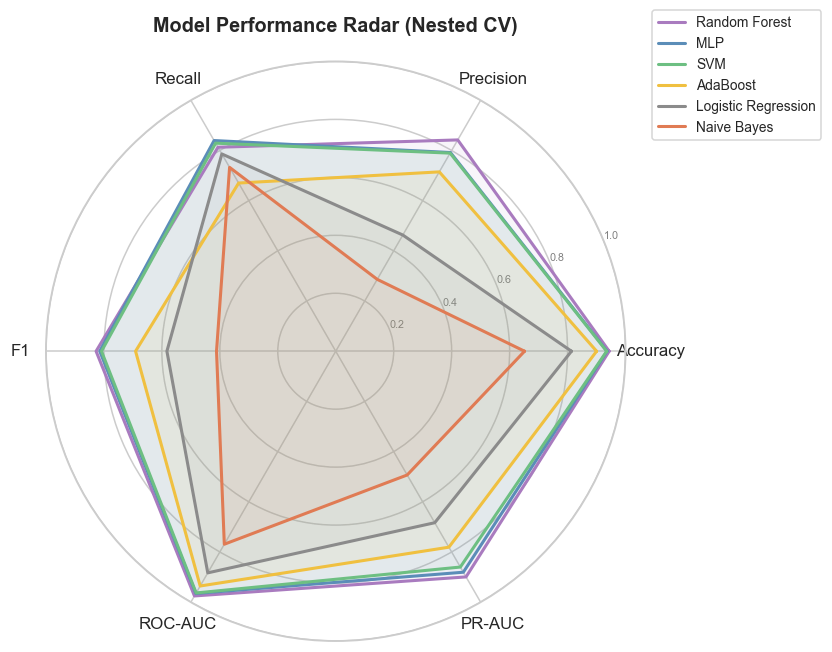

                     CV ROC-AUC  CV PR-AUC   CV F1  Test ROC-AUC  Test PR-AUC  Test F1  Train-Val AUC Gap Overfit Risk Underfit Risk CV Stability
Model                                                                                                                                            
Random Forest            0.9752     0.8993  0.8270        0.9818       0.9446   0.8875             0.0248          MED            NO          MED
MLP                      0.9653     0.8806  0.8143        0.9820       0.9198   0.8721             0.0326          MED            NO          MED
SVM                      0.9633     0.8600  0.8083        0.9742       0.9135   0.8653             0.0343          MED            NO         HIGH
AdaBoost                 0.9355     0.7809  0.6908        0.9406       0.7907   0.7160             0.0439          MED            NO          MED
Logistic Regression      0.8832     0.6834  0.5826        0.8618       0.6635   0.5439             0.0083          LOW      

In [14]:
radar_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
N = len(radar_metrics)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
for name in model_names_sorted:
    vals = [summary.loc[name, m] for m in radar_metrics]
    vals += vals[:1]
    ax.plot(angles, vals, lw=2, color=PALETTE[name], label=name)
    ax.fill(angles, vals, alpha=0.07, color=PALETTE[name])
ax.set_xticks(angles[:-1]); ax.set_xticklabels(radar_metrics, fontsize=11)
ax.set_ylim(0, 1); ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=7, color="gray")
ax.set_title("Model Performance Radar (Nested CV)", fontsize=13, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout(); plt.show()

verdict = []
for name in model_names_sorted:
    res  = cv_results[name]
    auc  = res["test_roc_auc"].mean()
    stab = np.mean([res[f"test_{m}"].std() for m in ["accuracy", "f1", "roc_auc"]])
    gap  = summary.loc[name, "Train-Val AUC Gap (Δ)"]
    verdict.append({
        "Model":          name,
        "CV ROC-AUC":     round(auc, 4),
        "CV PR-AUC":      round(res["test_average_precision"].mean(), 4),
        "CV F1":          round(res["test_f1"].mean(), 4),
        "Test ROC-AUC":   round(test_summary.loc[name, "ROC-AUC"], 4),
        "Test PR-AUC":    round(test_summary.loc[name, "PR-AUC"], 4),
        "Test F1":        round(test_summary.loc[name, "F1"], 4),
        "Train-Val AUC Gap": round(gap, 4),
        "Overfit Risk":   "HIGH" if gap > 0.08 else ("LOW" if gap < 0.02 else "MED"),
        "Underfit Risk":  "YES" if auc < 0.70 else "NO",
        "CV Stability":   "HIGH" if stab < 0.015 else ("LOW" if stab > 0.04 else "MED"),
    })
vdf = pd.DataFrame(verdict).set_index("Model")
print(vdf.to_string())

# The best model is chosen on nested-CV ROC-AUC, not on the test set
best = vdf.index[0]
print(f"\nBest model (by nested-CV ROC-AUC): {best}")
print(f"  CV:   AUC={vdf.loc[best,'CV ROC-AUC']}, PR-AUC={vdf.loc[best,'CV PR-AUC']}, F1={vdf.loc[best,'CV F1']}")
print(f"  Test: AUC={vdf.loc[best,'Test ROC-AUC']}, PR-AUC={vdf.loc[best,'Test PR-AUC']}, F1={vdf.loc[best,'Test F1']}")
print(f"  Overfit risk: {vdf.loc[best,'Overfit Risk']}, Stability: {vdf.loc[best,'CV Stability']}")

**Radar chart:** the model with the largest polygon is the strongest across all six nested-CV metrics at once.

**Final verdict table:**
- **CV ROC-AUC / PR-AUC / F1:** nested-CV estimates on the training set. The best model is chosen on these, so the test set plays no part in model selection.
- **Test ROC-AUC / PR-AUC / F1:** the one-time check on the held-out 20%.
- **Train-Val AUC Gap, Overfit Risk:** ROC-AUC gap with the thresholds from Cell 7 (HIGH > 0.08, MED 0.02–0.08, LOW < 0.02).
- **Underfit Risk:** YES if CV ROC-AUC < 0.70.
- **CV Stability:** HIGH if the mean fold std < 0.015, LOW if > 0.04.

## Cell 14 — Feature Importance (Permutation Importance on the Test Set)

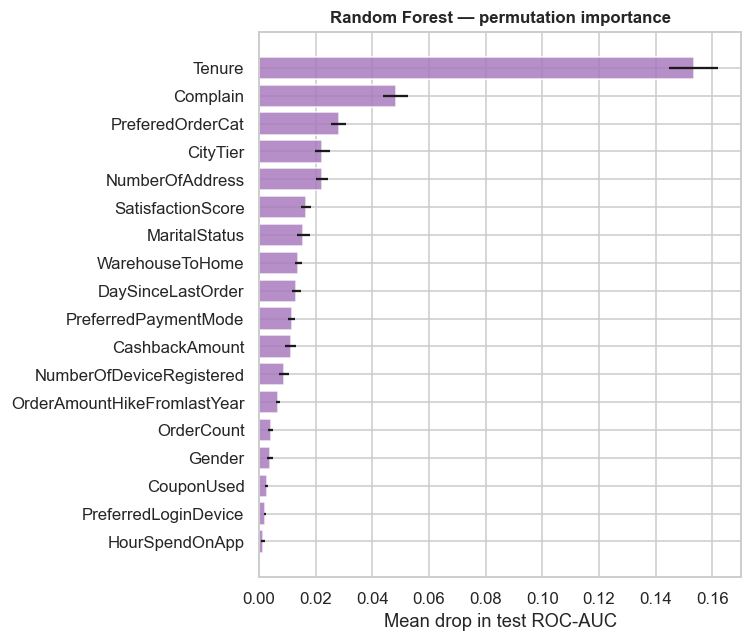


Top 5 features — Random Forest:
                    mean     std
Tenure            0.1535  0.0087
Complain          0.0482  0.0043
PreferedOrderCat  0.0281  0.0025
CityTier          0.0224  0.0027
NumberOfAddress   0.0222  0.0023


In [15]:
# Permutation importance: shuffle one original column at a time in the TEST set and measure
# how much ROC-AUC drops. It works for any model and is computed on data the model never saw.
fi_models = [best] + (["Random Forest"] if best != "Random Forest" else [])
fig, axes = plt.subplots(1, len(fi_models), figsize=(7*len(fi_models), 6), squeeze=False)
importances = {}

for ax, name in zip(axes[0], fi_models):
    pi = permutation_importance(MODELS[name], X_test, y_test, scoring="roc_auc",
                                n_repeats=5 if QUICK_MODE else 10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std},
                       index=X_test.columns).sort_values("mean")
    importances[name] = imp
    ax.barh(imp.index, imp["mean"], xerr=imp["std"], color=PALETTE[name], alpha=0.85)
    ax.set_title(f"{name} — permutation importance", fontsize=11, fontweight="bold")
    ax.set_xlabel("Mean drop in test ROC-AUC")

plt.tight_layout(); plt.show()

for name, imp in importances.items():
    print(f"\nTop 5 features — {name}:")
    print(imp.sort_values("mean", ascending=False).head(5).round(4).to_string())

Permutation importance is measured on the **original** columns (before one-hot encoding), so each bar is one business feature. A feature whose shuffling barely changes ROC-AUC contributes little to the model's predictions. Importance measures what the model *relies on*, not causation. Correlated features can also share or mask each other's importance.

## Conclusions & Final Commentary

*Written after the full run (`QUICK_MODE = False`, fixed `RANDOM_STATE = 42`); all numbers below come from the saved outputs above. A quick-mode run (the default on Colab) uses smaller grids and 3 outer folds, so its numbers differ slightly.*

**Setup.** After removing 557 duplicate rows, 5,073 customers remain (16.6% churn). 4,058 are used for training and model selection, and 1,015 (168 churners) are held out as a test set. Imputation, SMOTENC oversampling, scaling and one-hot encoding are all fitted inside each training fold. Hyperparameters are tuned with nested cross-validation, so neither the outer validation folds nor the test set influence tuning.

**Ranking (nested-CV ROC-AUC, mean ± std over 5 outer folds):**

| Model | CV ROC-AUC | CV PR-AUC | CV F1 | Test ROC-AUC | Test PR-AUC | Test F1 |
|---|---|---|---|---|---|---|
| Random Forest | 0.975 ± 0.006 | 0.899 | 0.827 | 0.982 | 0.945 | 0.888 |
| MLP | 0.965 ± 0.010 | 0.881 | 0.814 | 0.982 | 0.920 | 0.872 |
| SVM (rbf, C=10) | 0.963 ± 0.010 | 0.860 | 0.808 | 0.974 | 0.914 | 0.865 |
| AdaBoost | 0.936 ± 0.022 | 0.781 | 0.691 | 0.941 | 0.791 | 0.716 |
| Logistic Regression | 0.883 ± 0.020 | 0.683 | 0.583 | 0.862 | 0.664 | 0.544 |
| Naive Bayes | 0.769 ± 0.031 | 0.493 | 0.411 | 0.767 | 0.482 | 0.395 |

- **Random Forest** has the best nested-CV ROC-AUC, PR-AUC and F1, and the smallest fold-to-fold spread in ROC-AUC. It is selected as the best model on the CV results alone. On the test set it misses 22 of 168 churners and raises 15 false alarms.
- **MLP and SVM are close behind.** Their CV ROC-AUC is about 0.01 below Random Forest's, which is roughly one standard deviation, so the gap between the top three is small. On the test set both have **higher recall** than Random Forest (0.893 and 0.899 vs 0.869, i.e. 18 and 17 missed churners vs 22), paid for with more false alarms (26 and 30 vs 15). If missed churners are much more costly than wasted offers, they are reasonable alternatives.
- **The linear and probabilistic baselines are clearly weaker.** Logistic Regression (0.883) shows that a linear decision boundary leaves a lot of signal unused. Naive Bayes (0.769) is the weakest model. Its assumptions of independent, Gaussian-distributed features don't fit this data, which includes right-skewed counts, one-hot columns, and features likely related to each other such as `Tenure` and `CashbackAmount`. The notebook does not isolate which assumption costs the most.

**Test set vs nested CV.** For the top four models the test scores are slightly *higher* than the nested-CV estimates (for example Random Forest's test PR-AUC is 0.945 vs 0.899 in CV). This is consistent with two things the notebook shows. First, the final models train on all 4,058 training rows, while each CV model sees only about 3,250, and the learning curves are still rising at full size. Second, a single test set with 168 churners carries sampling noise. The nested-CV numbers are the more conservative estimate and the ones to quote.

**Overfitting / underfitting.**
- The ROC-AUC train-validation gap is **0.025–0.044** for Random Forest, MLP, SVM and AdaBoost (MED risk) and **below 0.01** for Logistic Regression and Naive Bayes (LOW). No model exceeds the 0.08 threshold. Random Forest reaches a training AUC of 1.0, so it does memorise its training rows. That doesn't hurt its ranking of new customers (validation AUC 0.975), but at the default threshold it shows up as a large F1 gap (about 0.17, Cell 9).
- The learning curves for Random Forest, MLP, SVM and AdaBoost are **still rising** at the full training size (validation AUC +0.008 to +0.010 over the last step), so more data would likely help them further.
- Logistic Regression and Naive Bayes have flat learning curves with train and validation close together. More data won't help them; they are limited by model capacity. Their AUCs are above the 0.70 underfitting threshold, but compared with the non-linear models they are **underfitting** this problem.

**Stability.** SVM is the most stable model (mean fold std below 0.015, rated HIGH). The others are rated MED. The chosen hyperparameters are also stable: SVM picked rbf with C=10 in all 5 folds, Naive Bayes the same smoothing in all 5, AdaBoost the same setting in 4 of 5, and Random Forest always 200 trees with deep trees (max_depth 20 or unlimited).

**Feature importance.** Permutation importance of Random Forest on the test set (Cell 14) ranks **`Tenure`** far above everything else (shuffling it lowers test AUC by 0.154). It is followed by **`Complain`** (0.048), `PreferedOrderCat` (0.028), `CityTier` (0.022) and `NumberOfAddress` (0.022). This shows what the model relies on, not what causes churn. Still, it suggests two places to look: the early months of a customer's lifetime, and how complaints are handled.

**Limitations and next steps.**
- All classification metrics use the default 0.5 threshold. The decision threshold could be tuned on the precision-recall curve to match the business cost of a missed churner versus a wasted offer, but that tuning must use the training folds, not the test set.
- SHAP values would explain individual predictions.
- Repeated nested CV, or several test splits, would narrow the uncertainty between the top three models.